In [43]:
%run "/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/code/Initialization/Initialization.ipynb"

# Analysis

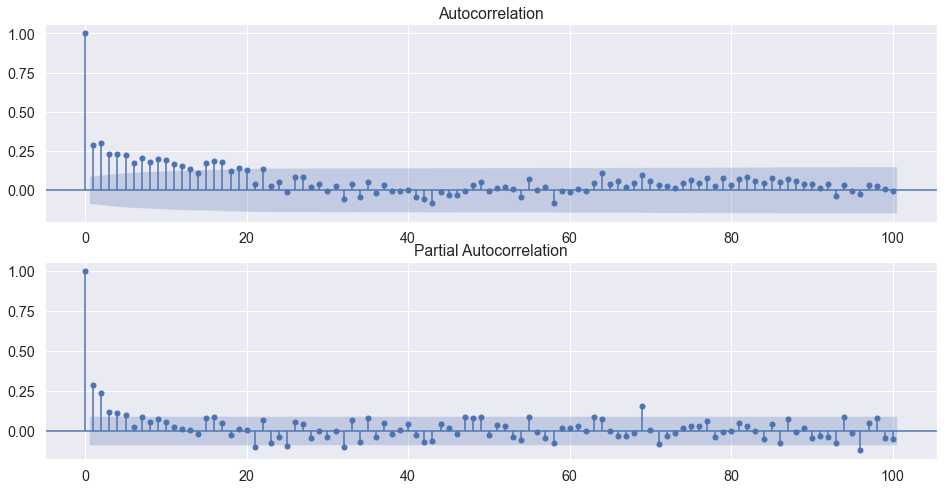

In [44]:
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.tsaplots import plot_pacf

f, ax = plt.subplots(nrows=2, ncols=1, figsize=(16, 8))

plot_acf(df['sentiment'], lags=100, ax=ax[0])
plot_pacf(df['sentiment'], lags=100, ax=ax[1])

plt.show()

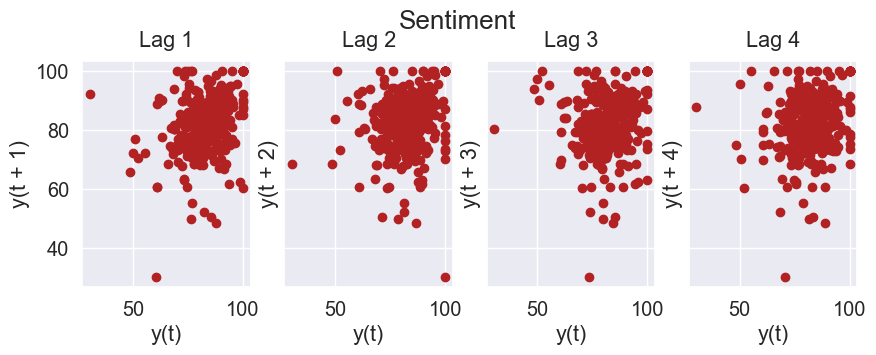

In [45]:
from pandas.plotting import lag_plot
plt.rcParams.update({'ytick.left' : False, 'axes.titlepad':10})

# Plot
fig, axes = plt.subplots(1, 4, figsize=(10,3), sharex=True, sharey=True, dpi=100)
for i, ax in enumerate(axes.flatten()[:4]):
    lag_plot(df_part3['sentiment'], lag=i+1, ax=ax, c='firebrick')
    ax.set_title('Lag ' + str(i+1))

fig.suptitle('Sentiment', y=1.05)    
plt.show()

In [46]:
from statsmodels.tsa.stattools import grangercausalitytests

grangercausalitytests(df_part3[['sentiment_ln_return', 'vix_ln_return']], maxlag=3, verbose=True)


Granger Causality
number of lags (no zero) 1
ssr based F test:         F=3.9579  , p=0.0475  , df_denom=313, df_num=1
ssr based chi2 test:   chi2=3.9959  , p=0.0456  , df=1
likelihood ratio test: chi2=3.9708  , p=0.0463  , df=1
parameter F test:         F=3.9579  , p=0.0475  , df_denom=313, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=2.1530  , p=0.1179  , df_denom=310, df_num=2
ssr based chi2 test:   chi2=4.3754  , p=0.1122  , df=2
likelihood ratio test: chi2=4.3453  , p=0.1139  , df=2
parameter F test:         F=2.1530  , p=0.1179  , df_denom=310, df_num=2

Granger Causality
number of lags (no zero) 3
ssr based F test:         F=1.4228  , p=0.2361  , df_denom=307, df_num=3
ssr based chi2 test:   chi2=4.3658  , p=0.2246  , df=3
likelihood ratio test: chi2=4.3358  , p=0.2274  , df=3
parameter F test:         F=1.4228  , p=0.2361  , df_denom=307, df_num=3


{1: ({'ssr_ftest': (3.9579435268450522, 0.047520688610530874, 313.0, 1),
   'ssr_chi2test': (3.995879087805229, 0.045611653306407575, 1),
   'lrtest': (3.970825750372569, 0.04629506452292972, 1),
   'params_ftest': (3.957943526845495, 0.04752068861051797, 313.0, 1.0)},
   array([[0., 1., 0.]])]),
 2: ({'ssr_ftest': (2.152985604421415, 0.11787035911081332, 310.0, 2),
   'ssr_chi2test': (4.375422357372552, 0.11217319943001414, 2),
   'lrtest': (4.345313043065289, 0.11387470413825888, 2),
   'params_ftest': (2.1529856044212017, 0.11787035911083843, 310.0, 2.0)},
   array([[0., 0., 1., 0., 0.],
          [0., 0., 0., 1., 0.]])]),
 3: ({'ssr_ftest': (1.4228376603732051, 0.23609683249195268, 307.0, 3),
   'ssr_chi2test': (4.3658406386695745, 0.22457373092230937, 3),
   'lrtest': (4.335767854414371, 0.22741560828564142, 3),
   'params_ftest': (1.4228376603732709, 0.23609683249192992, 307.0, 3.0)},
   array([[0., 0., 0., 1., 0., 0., 0.],
          [0., 0., 0., 0., 1., 0., 0.],
          [0., 0

In [47]:
grangercausalitytests(df_part3[['sentiment_ln_return', 'vix']], maxlag=3, verbose=False)

{1: ({'ssr_ftest': (1.767231869565603, 0.1846931279200888, 313.0, 1),
   'ssr_chi2test': (1.7841701941940273, 0.18163808328385156, 1),
   'lrtest': (1.7791522641944084, 0.18225345797231424, 1),
   'params_ftest': (1.7672318695658191, 0.18469312792005826, 313.0, 1.0)},
   array([[0., 1., 0.]])]),
 2: ({'ssr_ftest': (0.964192412067602, 0.3824314470261343, 310.0, 2),
   'ssr_chi2test': (1.9594878051696427, 0.3754072273623094, 2),
   'lrtest': (1.953418371292173, 0.3765482124418241, 2),
   'params_ftest': (0.9641924120675343, 0.38243144702615417, 310.0, 2.0)},
   array([[0., 0., 1., 0., 0.],
          [0., 0., 0., 1., 0.]])]),
 3: ({'ssr_ftest': (0.6226471037316885, 0.6008271330564352, 307.0, 3),
   'ssr_chi2test': (1.9105328068900673, 0.5911819591699674, 3),
   'lrtest': (1.9047439586736346, 0.5924108457281216, 3),
   'params_ftest': (0.6226471037316565, 0.6008271330564574, 307.0, 3.0)},
   array([[0., 0., 0., 1., 0., 0., 0.],
          [0., 0., 0., 0., 1., 0., 0.],
          [0., 0., 0.,

Posterior Inference {Causal Impact}
                          Average            Cumulative
Actual                    4118.36            226509.99
Prediction (s.d.)         3848.35 (23.06)    211659.44 (1268.56)
95% CI                    [3802.63, 3893.04] [209144.59, 214117.26]

Absolute effect (s.d.)    270.01 (23.06)     14850.55 (1268.56)
95% CI                    [225.32, 315.73]   [12392.73, 17365.4]

Relative effect (s.d.)    7.02% (0.6%)       7.02% (0.6%)
95% CI                    [5.86%, 8.2%]      [5.86%, 8.2%]

Posterior tail-area probability p: 0.0
Posterior prob. of a causal effect: 100.0%

For more details run the command: print(impact.summary('report'))
Analysis report {CausalImpact}


During the post-intervention period, the response variable had
an average value of approx. 4118.36. By contrast, in the absence of an
intervention, we would have expected an average response of 3848.35.
The 95% interval of this counterfactual prediction is [3802.63, 3893.04].
Subtracting 

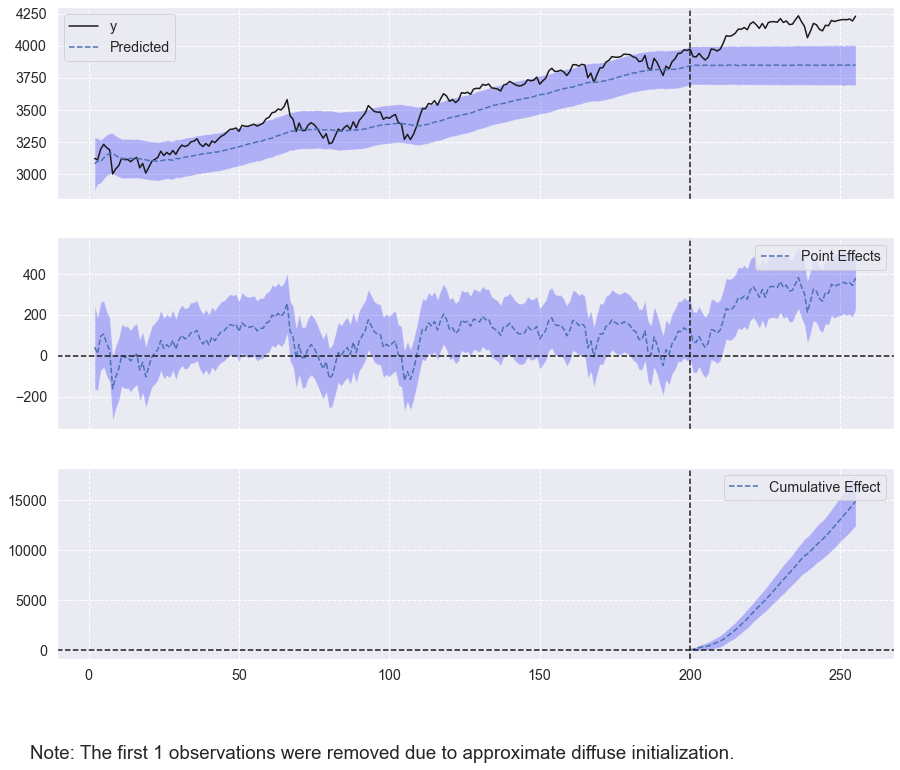

In [48]:
import matplotlib.pyplot as plt
import causalimpact
from statsmodels.tsa.arima_process import ArmaProcess
from causalimpact import CausalImpact

import datetime
# df["sentiment"] =df["sentiment"].fillna(0)
# df["vix"] =df["vix"].fillna(0)
# df_part3["sp500"] =df["sp500"].fillna(0)
df_part3.fillna(0, inplace=True)
data = df_part3[["sp500","sentiment"]].values.tolist()

pre_period = [1,200]
post_period = [201,255]
ci = CausalImpact(data, pre_period, post_period)
print(ci.summary())
print(ci.summary(output='report'))
ci.plot()

# Causal Impact

In [49]:
tsdata_to_autocov(df["sentiment"], df["vix"])

NameError: name 'tsdata_to_autocov' is not defined

10. How to test for stationarity?
The stationarity of a series can be established by looking at the plot of the series like we did earlier.

Another method is to split the series into 2 or more contiguous parts and computing the summary statistics like the mean, variance and the autocorrelation. If the stats are quite different, then the series is not likely to be stationary.

Nevertheless, you need a method to quantitatively determine if a given series is stationary or not. This can be done using statistical tests called ‘Unit Root Tests’. There are multiple variations of this, where the tests check if a time series is non-stationary and possess a unit root.

There are multiple implementations of Unit Root tests like:

1. Augmented Dickey Fuller test (ADH Test)
2. Kwiatkowski-Phillips-Schmidt-Shin – KPSS test (trend stationary)
3. Philips Perron test (PP Test)
The most commonly used is the ADF test, where the null hypothesis is the time series possesses a unit root and is non-stationary. So, id the P-Value in ADH test is less than the significance level (0.05), you reject the null hypothesis.

The KPSS test, on the other hand, is used to test for trend stationarity. The null hypothesis and the P-Value interpretation is just the opposite of ADH test. The below code implements these two tests using statsmodels package in python.

In [ ]:
from statsmodels.tsa.stattools import adfuller, kpss
df_vix_ln_return = pd.DataFrame()
df_vix_ln_return = df_part3[["vix_ln_return"]]
print(df_vix_ln_return)
# ADF Test
result = adfuller(df_vix_ln_return.vix_ln_return.values, autolag='AIC')
print(f'ADF Statistic: {result[0]}')
print(f'p-value: {result[1]}')
for key, vix_ln_return in result[4].items():
    print('Critial Values:')
    print(f'   {key}, {vix_ln_return}')

# KPSS Test
result = kpss(df_vix_ln_return.vix_ln_return.values, regression='c')
print('\nKPSS Statistic: %f' % result[0])
print('p-value: %f' % result[1])
for key, vix_ln_return in result[3].items():
    print('Critial Values:')
    print(f'   {key}, {vix_ln_return}')


In [ ]:
grangercausalitytests(df[['sentiment', 'month']], maxlag=2)

16. What is autocorrelation and partial autocorrelation functions?
Autocorrelation is simply the correlation of a series with its own lags. If a series is significantly autocorrelated, that means, the previous values of the series (lags) may be helpful in predicting the current value.
Partial Autocorrelation also conveys similar information but it conveys the pure correlation of a series and its lag, excluding the correlation contributions from the intermediate lags.

In [ ]:
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

df = pd.read_csv('https://raw.githubusercontent.com/selva86/datasets/master/a10.csv')

# Calculate ACF and PACF upto 50 lags
# acf_50 = acf(df.value, nlags=50)
# pacf_50 = pacf(df.value, nlags=50)

# Draw Plot
fig, axes = plt.subplots(1,2,figsize=(16,3), dpi= 100)
plot_acf(df.value.tolist(), lags=50, ax=axes[0])
plot_pacf(df.value.tolist(), lags=50, ax=axes[1])

17. How to compute partial autocorrelation function?
So how to compute partial autocorrelation?

The partial autocorrelation of lag (k) of a series is the coefficient of that lag in the autoregression equation of Y. The autoregressive equation of Y is nothing but the linear regression of Y with its own lags as predictors.

For Example, if Y_t is the current series and Y_t-1 is the lag 1 of Y, then the partial autocorrelation of lag 3 (Y_t-3) is the coefficient $\alpha_3$ of Y_t-3 in the following equation: